<a href="https://colab.research.google.com/github/LadybugEngineer7/iaasse-member-conversion-prediction/blob/main/Member_Conversion_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Member Conversion Prediction Model (IAASSE)
**Synthetic educational data - not real IAASSE members. Results are not validated on real members.**

## 1. Load and inspect

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/data.csv")   # change the path if needed
print(df.shape)
df.head()

(15000, 10)


,Member_ID,Days_Since_Registration,Login_Count,Events_Attended,Courses_Completed,Engagement_Score,Email_Clicks,Referral_Source,Membership_Duration_Days,Converted
0,IAS00001,234,8,1,1,44,3,Other,186,0
1,IAS00002,74,9,2,3,74,5,Friend,63,0
2,IAS00003,343,9,0,1,32,3,Website,333,0
3,IAS00004,403,6,0,1,25,8,Social Media,393,0
4,IAS00005,34,4,1,0,0,3,Website,32,0


In [ ]:
df.info()
print(df.isnull().sum())
print("Duplicate IDs:", df["Member_ID"].duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Member_ID                 15000 non-null  object
 1   Days_Since_Registration   15000 non-null  int64 
 2   Login_Count               15000 non-null  int64 
 3   Events_Attended           15000 non-null  int64 
 4   Courses_Completed         15000 non-null  int64 
 5   Engagement_Score          15000 non-null  int64 
 6   Email_Clicks              15000 non-null  int64 
 7   Referral_Source           15000 non-null  object
 8   Membership_Duration_Days  15000 non-null  int64 
 9   Converted                 15000 non-null  int64 
dtypes: int64(8), object(2)
memory usage: 1.1+ MB
Member_ID                   0
Days_Since_Registration     0
Login_Count                 0
Events_Attended             0
Courses_Completed           0
Engagement_Score            0
Email_Clicks 

,count,mean,std,min,25%,50%,75%,max
Days_Since_Registration,15000.0,250.573533,223.396011,7.0,101.0,178.0,315.0,1095.0
Login_Count,15000.0,6.790867,5.195357,0.0,3.0,6.0,9.0,54.0
Events_Attended,15000.0,0.793200,1.064006,0.0,0.0,0.0,1.0,9.0
Courses_Completed,15000.0,0.507267,0.773641,0.0,0.0,0.0,1.0,8.0
Engagement_Score,15000.0,28.618467,21.657058,0.0,12.0,25.0,41.0,100.0
Email_Clicks,15000.0,3.227200,2.125029,0.0,2.0,3.0,4.0,16.0
Membership_Duration_Days,15000.0,208.019733,190.898571,5.0,81.0,145.0,263.0,1094.0
Converted,15000.0,0.219267,0.413763,0.0,0.0,0.0,0.0,1.0


## 2. Explore (plots BEFORE any scaling, so values stay 0-100)

Converted
0    0.781
1    0.219
Name: proportion, dtype: float64


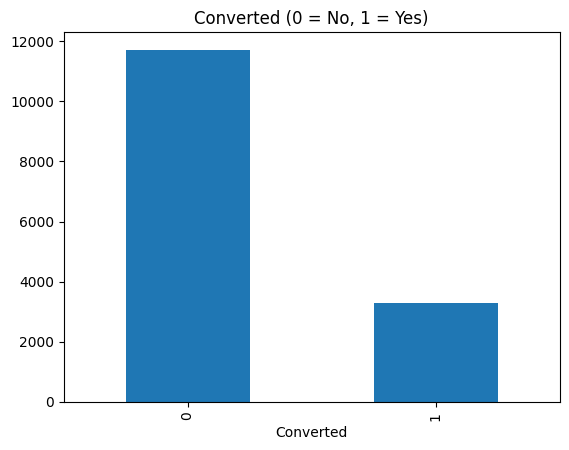

In [ ]:
print(df["Converted"].value_counts(normalize=True).round(3))
df["Converted"].value_counts().plot(kind="bar")
plt.title("Converted (0 = No, 1 = Yes)")
plt.show()

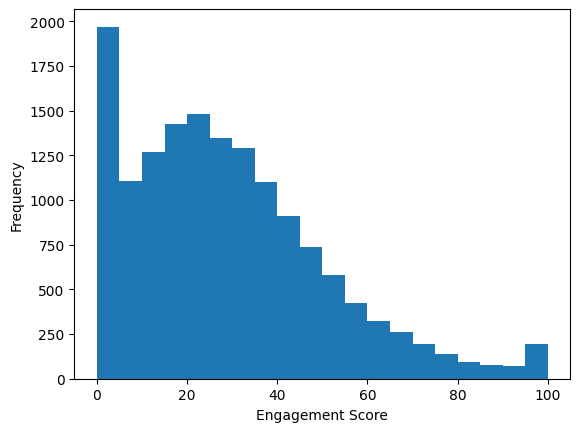

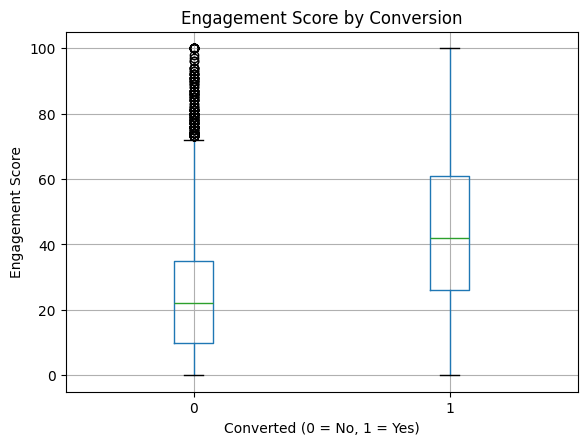

In [ ]:
plt.hist(df["Engagement_Score"], bins=20)
plt.xlabel("Engagement Score"); plt.ylabel("Frequency")
plt.show()

df.boxplot(column="Engagement_Score", by="Converted")
plt.title("Engagement Score by Conversion"); plt.suptitle("")
plt.xlabel("Converted (0 = No, 1 = Yes)"); plt.ylabel("Engagement Score")
plt.show()

## 3. Preprocess
Important order: **split first, scale after.**
Fitting the scaler on all data before splitting lets information from the test set leak into training.

In [ ]:
df = df.drop(columns=["Member_ID"])                       # identifier, not a feature
df = pd.get_dummies(df, columns=["Referral_Source"], dtype=int)

X = df.drop(columns=["Converted"])
y = df["Converted"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)    # stratify keeps ~22% converters in both sets
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(12000, 12) (3000, 12)
0.219 0.219


In [ ]:
from sklearn.preprocessing import MinMaxScaler

num_cols = ['Days_Since_Registration', 'Login_Count', 'Events_Attended',
            'Courses_Completed', 'Engagement_Score', 'Email_Clicks',
            'Membership_Duration_Days']

scaler = MinMaxScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit on TRAIN only
X_test_s[num_cols] = scaler.transform(X_test[num_cols])          # only transform on test

## 4. Train
`class_weight="balanced"` makes the models pay more attention to the small class (converters).
The Decision Tree depth is limited to reduce overfitting.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}

for name, model in models.items():
    model.fit(X_train_s, y_train)       # same scaled data for ALL models (trees are not affected by scaling)

## 5. Evaluate

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

rows = []
for name, model in models.items():
    pred = model.predict(X_test_s)
    proba = model.predict_proba(X_test_s)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC_AUC": roc_auc_score(y_test, proba)})

results = pd.DataFrame(rows).set_index("Model").round(3)
print("Baseline accuracy (always predict 'not converted'):", round(1 - y_test.mean(), 3))
results

Baseline accuracy (always predict 'not converted'): 0.781


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.728,0.423,0.660,0.515,0.764
Decision Tree,0.723,0.411,0.609,0.491,0.739
Random Forest,0.778,0.495,0.486,0.490,0.741


In [ ]:
for name, model in models.items():
    print("=====", name, "=====")
    print(classification_report(y_test, model.predict(X_test_s),
                                target_names=["Not converted", "Converted"], zero_division=0))

===== Logistic Regression =====
               precision    recall  f1-score   support

Not converted       0.89      0.75      0.81      2342
    Converted       0.42      0.66      0.52       658

     accuracy                           0.73      3000
    macro avg       0.65      0.70      0.66      3000
 weighted avg       0.78      0.73      0.75      3000

===== Decision Tree =====
               precision    recall  f1-score   support

Not converted       0.87      0.75      0.81      2342
    Converted       0.41      0.61      0.49       658

     accuracy                           0.72      3000
    macro avg       0.64      0.68      0.65      3000
 weighted avg       0.77      0.72      0.74      3000

===== Random Forest =====
               precision    recall  f1-score   support

Not converted       0.86      0.86      0.86      2342
    Converted       0.49      0.49      0.49       658

     accuracy                           0.78      3000
    macro avg       0.68    

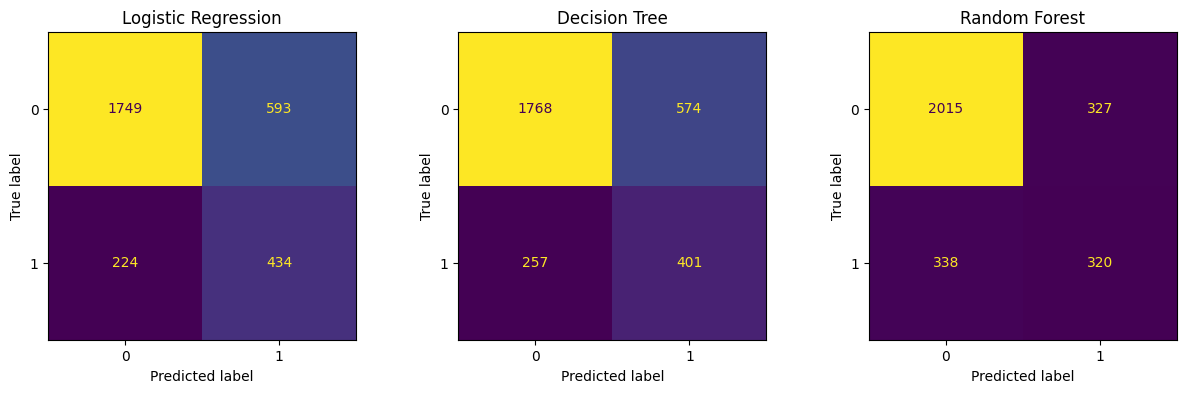

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test_s, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

## 6. Feature importance

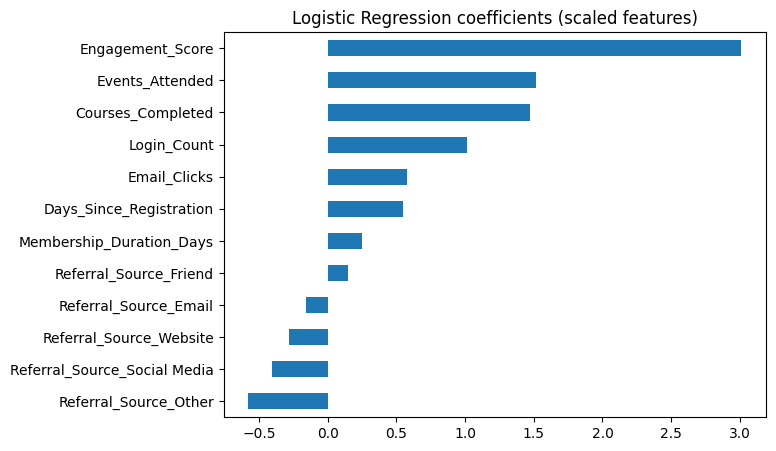

In [ ]:
lr = models["Logistic Regression"]
coef = pd.Series(lr.coef_[0], index=X_train_s.columns).sort_values()
coef.plot(kind="barh", figsize=(7, 5), title="Logistic Regression coefficients (scaled features)")
plt.show()

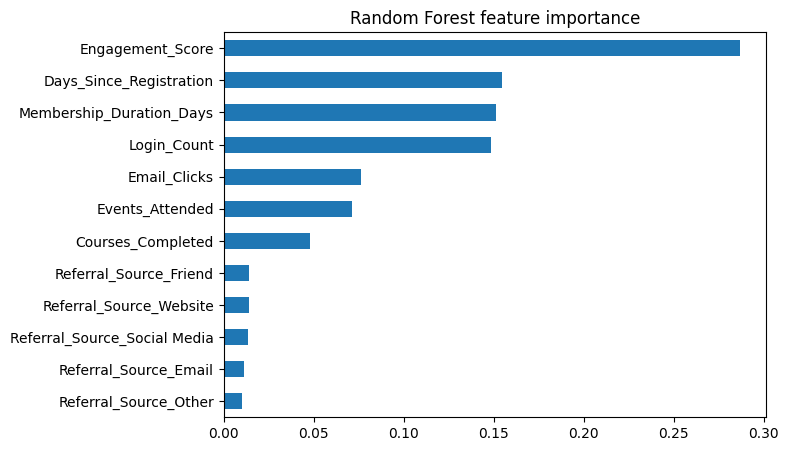

In [ ]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X_train_s.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title="Random Forest feature importance")
plt.show()

## 7. Notes, leakage and limitations
- **Synthetic data.** The relationships were designed by me; they do not describe real IAASSE members.
- **Accuracy is misleading** because only ~22% of members convert. Always predicting "not converted" already gives ~78%. Use recall, precision, F1 and ROC-AUC for the converted class.
- **Possible leakage:** `Membership_Duration_Days` must not include paid time; `Engagement_Score` is derived from other columns; scaling was fitted on the training set only.
- Correlated features (e.g. Engagement_Score and its components) make individual importances unstable.
- No hyperparameter tuning, probability calibration or threshold selection was done.
- The model is not validated on real members and must not be used for real decisions.

In [ ]:
!pip install gradio

In [ ]:
df.columns

Index(['Days_Since_Registration', 'Login_Count', 'Events_Attended',
       'Courses_Completed', 'Engagement_Score', 'Email_Clicks',
       'Membership_Duration_Days', 'Converted', 'Referral_Source_Email',
       'Referral_Source_Friend', 'Referral_Source_Other',
       'Referral_Source_Social Media', 'Referral_Source_Website'],
      dtype='object')

In [ ]:
import gradio as gr
import pandas as pd

def Predicting_Member_Conversion(
    Days_Since_Registration,
    Login_Count,
    Events_Attended,
    Courses_Completed,
    Engagement_Score,
    Email_Clicks,
    Membership_Duration_Days,
    Referral_Source
):
    input_data = pd.DataFrame({
        "Days_Since_Registration": [Days_Since_Registration],
        "Login_Count": [Login_Count],
        "Events_Attended": [Events_Attended],
        "Courses_Completed": [Courses_Completed],
        "Engagement_Score": [Engagement_Score],
        "Email_Clicks": [Email_Clicks],
        "Membership_Duration_Days": [Membership_Duration_Days],
        "Referral_Source_Email": [int(Referral_Source == "Email")],
        "Referral_Source_Friend": [int(Referral_Source == "Friend")],
        "Referral_Source_Other": [int(Referral_Source == "Other")],
        "Referral_Source_Social Media": [
            int(Referral_Source == "Social Media")
        ],
        "Referral_Source_Website": [
            int(Referral_Source == "Website")
        ]
    })

    prediction = models["Logistic Regression"].predict(input_data)

    if prediction[0] == 0:
        return "No Conversion (0)"
    else:
        return "Conversion Predicted (1)"


gr.Interface(
    fn=Predicting_Member_Conversion,
    inputs=[
        gr.Number(label="Days Since Registration", value=100),
        gr.Number(label="Login Count", value=8),
        gr.Number(label="Events Attended", value=2),
        gr.Number(label="Courses Completed", value=1),
        gr.Number(label="Engagement Score", value=50),
        gr.Number(label="Email Clicks", value=3),
        gr.Number(label="Membership Duration Days", value=90),
        gr.Dropdown(
            choices=["Email", "Friend", "Other", "Social Media", "Website"],
            label="Referral Source"
        )
    ],
    outputs=gr.Textbox(label="Member Conversion Prediction"),
    title="Member Conversion Prediction"
).launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2cb60e57b8e3c699e7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
